In [1]:
## Outdated... see CAMP2Ex_overview.ipynb

import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
terra_time = np.datetime64('2019-10-02T02:40:00')

In [3]:
bulk_props_file = '../../data/CAMP2Ex_SPEC/CAMP2Ex-CloudBulkProps_P3B_20191001_R0.ICT'
nav_file = '../../data/CAMP2Ex_SPEC/CAMP2EX-MetNav_P3B_20191001_R0.ict'
bulk_props = pd.read_csv(bulk_props_file, skiprows=37, header=0, index_col=0)
nav = pd.read_csv(nav_file, skiprows=73, header=0, index_col=0)
bulk_props.index = pd.to_datetime(bulk_props.index, unit='s', origin=pd.Timestamp('2019-10-01'))
bulk_props.index.name = 'time'
bulk_props = bulk_props.to_xarray()
nav.index = pd.to_datetime(nav.index, unit='s', origin=pd.Timestamp('2019-10-01'))
nav.index.name = 'time'
nav = nav.to_xarray()
data = xr.merge([bulk_props, nav])
nan_reff = data.Reff_um.copy(deep=True).data
nan_reff[nan_reff == 0] = np.nan
data['Reff_um'] = (['time'], nan_reff)

In [4]:
data_subset = data.sel(time=slice('2019-10-02T00:00:00', '2019-10-02T02:00:00'))
data_subset

<xarray.Dataset> Size: 2MB
Dimensions:                 (time: 7201)
Coordinates:
  * time                    (time) datetime64[ns] 58kB 2019-10-02 ... 2019-10...
Data variables: (12/40)
    CP_Type                 (time) int64 58kB 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0
    Concentration_L         (time) int64 58kB 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0
    IWC_gm3                 (time) float64 58kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    LWC_gm3                 (time) float64 58kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    Reff_um                 (time) float64 58kB nan nan nan nan ... nan nan nan
    Z_dBz                   (time) float64 58kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    ...                      ...
    Aircraft_Sun_Azimuth    (time) float64 58kB 72.3 72.4 72.3 ... -139.4 -139.4
    Mixing_Ratio            (time) float64 58kB 19.08 19.14 19.09 ... 12.9 12.89
    Part_Press_Water_Vapor  (time) float64 58kB 29.07 29.16 ... 18.18 18.16
    Sat_Vapor_Press_H2O     (time) float64 58kB 31.4 31.33 31.52 ... 25.06 25.14
    Sat_Vapor_Press_Ice     (time) float64 58kB 39.81 39.71 40.0 ... 30.68 30.79
    Relative_Humidity       (time) float64 58kB 92.6 93.07 92.27 ... 72.53 72.23

In [5]:
from sklearn.linear_model import LinearRegression
# Prepare the data
y = data_subset['Reff_um'].data
cloud_cond = ~np.isnan(y)
y = y[cloud_cond]
X = data_subset['GPS_Altitude'].data / 1000
X = X[cloud_cond].reshape(-1, 1)

# Create an instance of the LinearRegression model
model = LinearRegression()

# Fit the model to the data
model.fit(X, y)

# Print the regression results
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_)


Intercept: 2.991867942556189
Coefficient: [4.41088483]


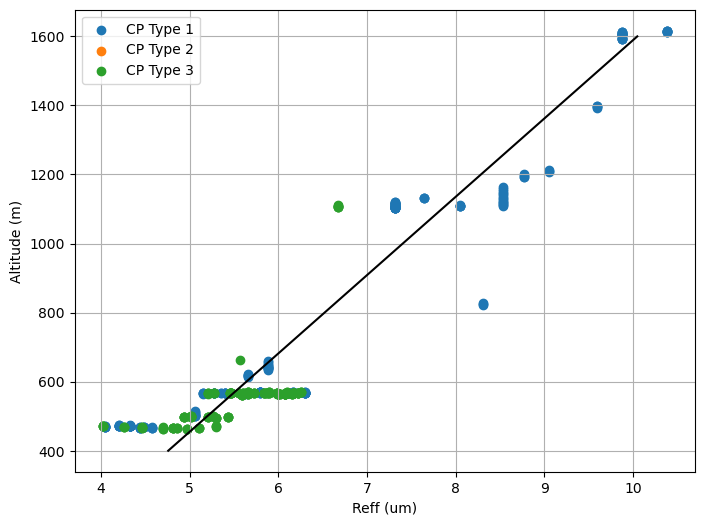

In [6]:
f, ax = plt.subplots(1, 1, figsize=(8, 6))
cp_type1 = data_subset.CP_Type.data == 1
cp_type2 = data_subset.CP_Type.data == 2
cp_type3 = data_subset.CP_Type.data == 3
ax.scatter(data_subset.Reff_um.data[cp_type1], data_subset.GPS_Altitude[cp_type1], label='CP Type 1')
ax.scatter(data_subset.Reff_um.data[cp_type2], data_subset.GPS_Altitude[cp_type2], label='CP Type 2')
ax.scatter(data_subset.Reff_um.data[cp_type3], data_subset.GPS_Altitude[cp_type3], label='CP Type 3')
z = np.linspace(400, 1600, 200)
re = model.intercept_ + model.coef_ * z/1000
ax.plot(re, z, color='black')
ax.set_xlabel('Reff (um)')
ax.set_ylabel('Altitude (m)')
ax.grid()
ax.legend()
# ax.set_xlim(0, 28)
# ax.set_ylim(0, 1200)
